# Baseline Forecast Evaluation

This notebook fits and evaluates the simple baseline proposed in Milestone 1.

**Baseline rule:**
- Returning Premier League teams are predicted to finish with the same number of points they earned in the previous season.
- Newly promoted teams do not have previous-season EPL points, so they receive the average final points from the training data only.

The project makes predictions after Match 10, so the forecast horizon is the remaining 28 matches. This baseline intentionally does not use the first 10 matches of the current season because it is meant to be a simple reference for later models.




### A. Import Statements & Data Load

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

season_results = pd.read_excel("epl_match_data.xlsx", sheet_name = "Season Results Data")
season_results


,Season,Team,Total_Points
0,2015,Leicester,81
1,2015,Arsenal,71
2,2015,Tottenham,70
3,2015,Manchester City,66
4,2015,Manchester United,66
...,...,...,...
215,2025,Nottingham Forest,44
216,2025,Tottenham,41
217,2025,West Ham,39
218,2025,Burnley,22


### B. Baseline Data Setup

The first season in the dataset (2015/16) is used to provide previous-season points for 2016/17. Because the baseline needs a previous EPL season, the target seasons begin in 2016/17.


In [21]:
# Create previous-season points for each club
previous_season = season_results[["Season", "Team", "Total_Points"]].copy()
previous_season["Season"] = previous_season["Season"] + 1
previous_season = previous_season.rename(columns = {"Total_Points": "Previous_Season_Points"})

baseline_data = season_results.merge(previous_season, on = ["Season", "Team"], how = "left")
baseline_data = baseline_data[baseline_data["Season"] >= 2016].copy()

# If previous-season EPL points are missing, the club is treated as newly promoted
baseline_data["Promoted"] = baseline_data["Previous_Season_Points"].isna()

print(f"Usable club-seasons: {len(baseline_data)}")
print(f"Target seasons: {baseline_data['Season'].min()}/{str(baseline_data['Season'].min() + 1)[-2:]} through {baseline_data['Season'].max()}/{str(baseline_data['Season'].max() + 1)[-2:]}")
baseline_data


Usable club-seasons: 200
Target seasons: 2016/17 through 2025/26


,Season,Team,Total_Points,Previous_Season_Points,Promoted
20,2016,Chelsea,93,50.0,False
21,2016,Tottenham,86,70.0,False
22,2016,Manchester City,78,66.0,False
23,2016,Liverpool,76,60.0,False
24,2016,Arsenal,75,71.0,False
...,...,...,...,...,...
215,2025,Nottingham Forest,44,65.0,False
216,2025,Tottenham,41,38.0,False
217,2025,West Ham,39,43.0,False
218,2025,Burnley,22,NaN,True


### C. Chronological Train/Test Split

We use the first seven usable seasons for training and the last three seasons for testing.

- **Training:** 2016/17–2022/23
- **Testing:** 2023/24–2025/26

The same split can be kept for the later multiple linear regression models so that all models are evaluated on the same unseen seasons.


In [15]:
# Time-ordered split
train_data = baseline_data[(baseline_data["Season"] >= 2016) & (baseline_data["Season"] <= 2022)].copy()
test_data = baseline_data[(baseline_data["Season"] >= 2023) & (baseline_data["Season"] <= 2025)].copy()

# Training mean is used only when a test team was not in the EPL during the previous season
training_mean = train_data["Total_Points"].mean()

print(f"Training observations: {len(train_data)}")
print(f"Testing observations: {len(test_data)}")
print(f"Promoted teams in training data: {int(train_data['Promoted'].sum())}")
print(f"Promoted teams in testing data: {int(test_data['Promoted'].sum())}")
print(f"Training average final points: {training_mean:.2f}")


Training observations: 140
Testing observations: 60
Promoted teams in training data: 21
Promoted teams in testing data: 9
Training average final points: 52.69


### D. Generate Baseline Predictions

For returning teams, the forecast equals their previous-season final points. For promoted teams, the forecast equals the training-set average. A training-mean prediction for every team is also included as a simpler reference comparison.


In [16]:
# Milestone 1 baseline prediction
test_data["Baseline_Prediction"] = test_data["Previous_Season_Points"].fillna(training_mean)

# Simpler reference prediction: training mean for every test team
test_data["Training_Mean_Reference"] = training_mean

# Forecast errors
test_data["Error"] = test_data["Total_Points"] - test_data["Baseline_Prediction"]
test_data["Squared_Error"] = test_data["Error"] ** 2
test_data["Absolute_Error"] = test_data["Error"].abs()

prediction_table = test_data[[
    "Season", "Team", "Total_Points", "Previous_Season_Points", "Promoted",
    "Baseline_Prediction", "Error"
]].copy()

prediction_table["Baseline_Prediction"] = prediction_table["Baseline_Prediction"].round(2)
prediction_table["Error"] = prediction_table["Error"].round(2)
display(prediction_table)


,Season,Team,Total_Points,Previous_Season_Points,Promoted,Baseline_Prediction,Error
160,2023,Manchester City,91,89.0,False,89.00,2.00
161,2023,Arsenal,89,84.0,False,84.00,5.00
162,2023,Liverpool,82,67.0,False,67.00,15.00
163,2023,Aston Villa,68,61.0,False,61.00,7.00
164,2023,Tottenham,66,60.0,False,60.00,6.00
165,2023,Chelsea,63,44.0,False,44.00,19.00
166,2023,Manchester United,60,75.0,False,75.00,-15.00
167,2023,Newcastle United,60,71.0,False,71.00,-11.00
168,2023,West Ham,52,40.0,False,40.00,12.00
169,2023,Crystal Palace,49,45.0,False,45.00,4.00


### E. Overall Baseline Performance

MSE is the main evaluation metric because it gives more weight to larger prediction errors. MAD is also reported because it is easier to interpret directly in league points.


In [17]:
# Baseline performance
baseline_mse = test_data["Squared_Error"].mean()
baseline_mad = test_data["Absolute_Error"].mean()
baseline_mean_error = test_data["Error"].mean()

# Training-mean reference performance
reference_error = test_data["Total_Points"] - test_data["Training_Mean_Reference"]
reference_mse = (reference_error ** 2).mean()
reference_mad = reference_error.abs().mean()

performance_table = pd.DataFrame({
    "Model": ["Previous-season persistence baseline", "Training-mean reference"],
    "Test MSE": [baseline_mse, reference_mse],
    "Test MAD": [baseline_mad, reference_mad]
})
performance_table[["Test MSE", "Test MAD"]] = performance_table[["Test MSE", "Test MAD"]].round(2)

display(performance_table)
print(f"Baseline mean error (Actual - Predicted): {baseline_mean_error:.2f} points")


,Model,Test MSE,Test MAD
0,Previous-season persistence baseline,268.57,12.78
1,Training-mean reference,323.28,13.94


Baseline mean error (Actual - Predicted): -4.60 points


### F. Performance by Test Season

In [18]:
# Check whether baseline performance changes across the three test seasons
season_metrics = []

for season in sorted(test_data["Season"].unique()):
    season_data = test_data[test_data["Season"] == season]
    season_metrics.append({
        "Season": f"{season}/{str(season + 1)[-2:]}",
        "Observations": len(season_data),
        "MSE": season_data["Squared_Error"].mean(),
        "MAD": season_data["Absolute_Error"].mean(),
        "Mean_Error": season_data["Error"].mean()
    })

season_metrics = pd.DataFrame(season_metrics)
season_metrics[["MSE", "MAD", "Mean_Error"]] = season_metrics[["MSE", "MAD", "Mean_Error"]].round(2)
display(season_metrics)


,Season,Observations,MSE,MAD,Mean_Error
0,2023/24,20,243.29,12.55,-3.75
1,2024/25,20,350.67,14.95,-4.55
2,2025/26,20,211.73,10.83,-5.50


### G. Forecast Error Checks

A useful question for this baseline is whether it performs differently for returning teams and promoted teams. Promoted teams do not have previous-season EPL points, so their predictions depend entirely on the training mean.


In [19]:
# Compare forecast errors for returning and promoted teams
status_metrics = []

for promoted in [False, True]:
    status_data = test_data[test_data["Promoted"] == promoted]
    status_metrics.append({
        "Team_Status": "Promoted" if promoted else "Returning",
        "Observations": len(status_data),
        "MSE": status_data["Squared_Error"].mean(),
        "MAD": status_data["Absolute_Error"].mean(),
        "Mean_Error": status_data["Error"].mean()
    })

status_metrics = pd.DataFrame(status_metrics)
status_metrics[["MSE", "MAD", "Mean_Error"]] = status_metrics[["MSE", "MAD", "Mean_Error"]].round(2)
display(status_metrics)

# Show the largest absolute forecast errors
largest_errors = test_data.sort_values("Absolute_Error", ascending = False)[[
    "Season", "Team", "Total_Points", "Baseline_Prediction", "Error", "Promoted"
]].head(10).copy()
largest_errors[["Baseline_Prediction", "Error"]] = largest_errors[["Baseline_Prediction", "Error"]].round(2)

display(largest_errors)


,Team_Status,Observations,MSE,MAD,Mean_Error
0,Returning,51,174.39,10.55,-0.98
1,Promoted,9,802.22,25.42,-25.13


,Season,Team,Total_Points,Baseline_Prediction,Error,Promoted
199,2024,Southampton,12,52.69,-40.69,True
179,2023,Sheffield United,16,52.69,-36.69,True
186,2024,Nottingham Forest,65,32.00,33.00,False
218,2025,Burnley,22,52.69,-30.69,True
198,2024,Ipswich,22,52.69,-30.69,True
202,2025,Manchester United,71,42.00,29.00,False
178,2023,Burnley,24,52.69,-28.69,True
196,2024,Tottenham,38,66.00,-28.00,False
197,2024,Leicester,25,52.69,-27.69,True
177,2023,Luton,26,52.69,-26.69,True


### H. Baseline Prediction Plot

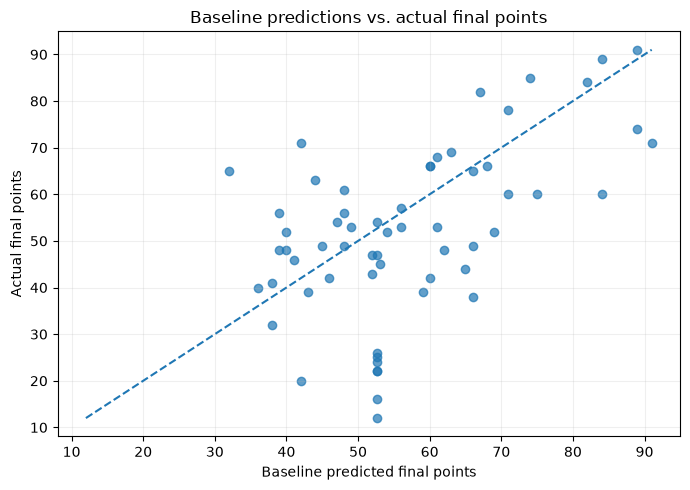

In [20]:
# Actual final points compared with the baseline prediction
plt.figure(figsize = (7, 5))
plt.scatter(test_data["Baseline_Prediction"], test_data["Total_Points"], alpha = 0.7)

plot_min = min(test_data["Baseline_Prediction"].min(), test_data["Total_Points"].min())
plot_max = max(test_data["Baseline_Prediction"].max(), test_data["Total_Points"].max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle = "--")

plt.xlabel("Baseline predicted final points")
plt.ylabel("Actual final points")
plt.title("Baseline predictions vs. actual final points")
plt.grid(alpha = 0.2)
plt.tight_layout()
plt.savefig("nicolas_baseline_predictions.png", dpi = 200)
plt.show()


### I. Initial Interpretation

Using the 2016/17–2022/23 seasons as training data and the 2023/24–2025/26 seasons as testing data, the previous-season persistence baseline has a test MSE of about **268.57** and a MAD of about **12.78 points**. This performs better than predicting the training-set average for every team, which has a test MSE of about **323.28**.

The baseline performs much worse for promoted teams because they do not have previous-season EPL points and are assigned the overall training mean. In the test data, promoted teams have much larger errors than returning teams. This is an important limitation of the baseline and gives later models a clear area where additional information may improve predictions.

This baseline gives the project a simple benchmark. Later models, including multiple linear regression using the full previous season, summer transfer information, and the first 10 matches of the current season, should be evaluated on the same test seasons and compared against these baseline results.
